# **National Parks Biodiversity: Observations by Conservation Status**

## **1. Project overview**

This notebook explores how recorded observation counts differ across conservation-status groups, for each species category. A grouped bar chart compares average observation counts across all categories. Box plots then look at the distribution within two categories, mammals and fish. Each box plot has a reference line marking one species of interest.

The input is the cleaned dataset from Notebook 1 (`species_observation_processed.csv`), which has one row per species.

The analysis is exploratory. Observation counts describe the records in this dataset. They should not be read as a measure of population size or as evidence of why a species has a given conservation status.

## **2. Objectives**

- Compare average observation counts across conservation statuses for every species category.
- Examine the distribution of observation counts within mammals and fish, using medians, quartiles, spread, and outliers.
- Compare the observation counts of *Canis lupus* (mammal) and *Oncorhynchus mykiss* (fish) with the distributions of their category's conservation-status groups.
- Identify patterns that may warrant further investigation.

## **3. Data loading and setup**
The cleaned dataset produced in Notebook 1 is loaded, and a working copy is made so the loaded data stays untouched. Pandas handles the data, and Matplotlib and Seaborn handle the plots.

In [1]:
# Import pandas for loading and analyzing tabular data.
import pandas as pd

# Import Matplotlib and Seaborn for creating visualizations.
import matplotlib.pyplot as plt
import seaborn as sns

# Import Path to build a platform-independent file path.
from pathlib import Path

# Define the path to the prepared dataset.
data_path = Path("../data/cleaned/species_observation_processed.csv")

# Load the cleaned dataset
df_temp = pd.read_csv(data_path)

# Create a working copy of the cleaned dataset to avoid modifying the original data.
df = df_temp.copy()

### **3.1 Previewing the data**
The table has four columns: `scientific_name`, `observations`, `category`, and `conservation_status`. Each row is one species. `conservation_status` is missing (`NaN`) for three of the five rows shown.

In [2]:
df.head()

,scientific_name,observations,category,conservation_status
0,Abies bifolia,532,Vascular Plant,NaN
1,Abies concolor,630,Vascular Plant,NaN
2,Abies fraseri,518,Vascular Plant,Species of Concern
3,Abietinella abietina,592,Nonvascular Plant,NaN
4,Abronia ammophila,523,Vascular Plant,Species of Concern


### **3.2 Preparing the Data for Plotting**
Missing values in `conservation_status` would be dropped from the plots. "Not listed" will be filled in them so those species appear as their own group.

"Not listed" is label added in this notebook. It most likely means no protected status was recorded, but the dataset does not define it.

In [3]:
df["conservation_status"] = df["conservation_status"].fillna("Not listed")

## **4. Average observations by category and conservation status**
The data is grouped by `category` and `conservation_status`, the mean observation count is calculated for each group, and the means are plotted as grouped bars. Each bar is a group mean, not a distribution. The statuses are ordered from highest to lowest risk, with "Not listed" last as a separate group.

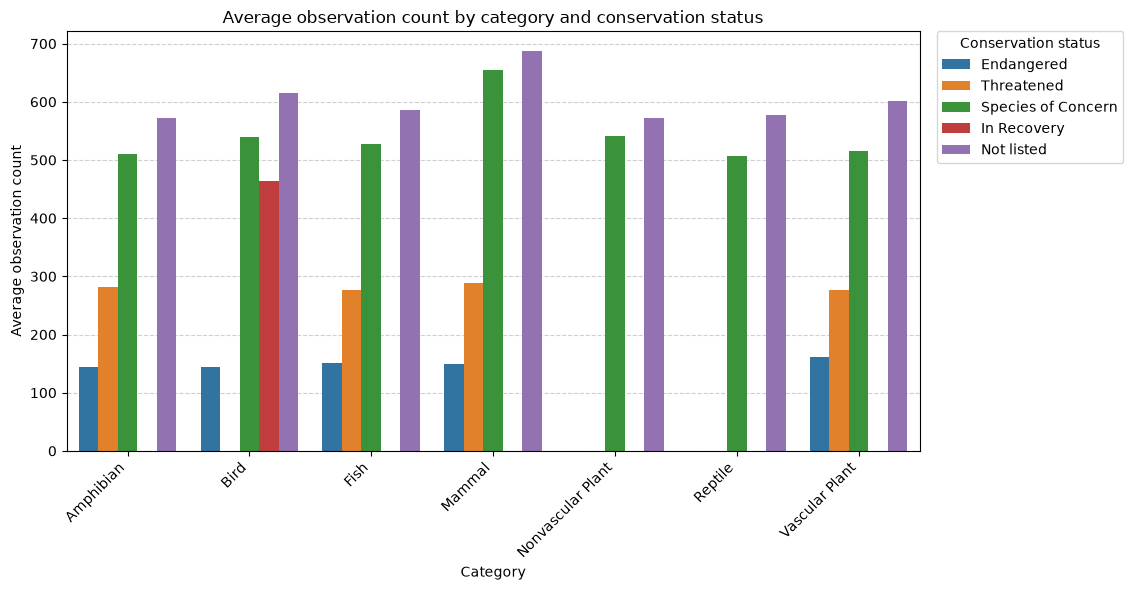

In [4]:
# Create a figure wide enough to fit the category labels and legend.
fig, ax = plt.subplots(figsize=(14, 6))

# Keep conservation statuses in a consistent, meaningful order in the legend.
risk_order = ["Endangered", "Threatened", "Species of Concern", "In Recovery", "Not listed"]

# Calculate the average observation count for each category and conservation status.
means = (
    df.groupby(["category", "conservation_status"], as_index=False)
      ["observations"]
      .mean()
)

# Plot the averages, grouping bars by conservation status within each category.
ax = sns.barplot(
    data=means,
    x="category",
    y="observations",
    hue="conservation_status",
    hue_order=risk_order,
    ax=ax
)

# Label the axes and describe what the chart shows.
ax.set(
    xlabel="Category",
    ylabel="Average observation count",
    title="Average observation count by category and conservation status"
)

# Place the legend outside the plot so it does not cover the bars.
ax.legend(
    title="Conservation status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

# Keep gridlines behind the bars and use subtle horizontal guides for comparison.
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.6)

# Rotate category labels to make them easier to read.
plt.xticks(rotation=45, ha="right")

# Reserve space on the right for the legend and adjust the layout.
fig.tight_layout(rect=[0, 0, 0.82, 1])

# Display the completed chart.
plt.show()

**Observations from the chart**
- In every category, average observations are lowest for Endangered species (about 145 to 160) and higher for the other statuses.
- Threatened species average about 280 where they appear (Amphibian, Fish, Mammal, Vascular Plant).
- Species of Concern average about 510 to 655, and Not listed species average about 570 to 690.
- Averages generally rise as risk falls (Endangered, then Threatened, then Species of Concern, then Not listed), and this pattern is similar across categories.
- Not every category has every status. Bird is the only category with In Recovery species (about 465, between Threatened and Species of Concern). Reptile and Nonvascular Plant have only Species of Concern and Not listed. Bird has no Threatened species.
- Mammal has the highest averages for Species of Concern and Not listed.

**Interpretation**
Not listed species have the highest average counts in every category. This is consistent with at-risk species being recorded less often, but the data cannot show *why*. Observation counts also depend on survey effort, how easily a species is detected, and park coverage. Some groups are small (for example, only a handful of Endangered species per category), so their averages are less stable.

## **5. Case Studies**
### **5.1 Review records for *Canis lupus***
**Goal:** Check whether the *Canis lupus* (gray wolf) observation count is similar to mammals labelled *Not listed*, by comparing it with mammals in each conservation status.

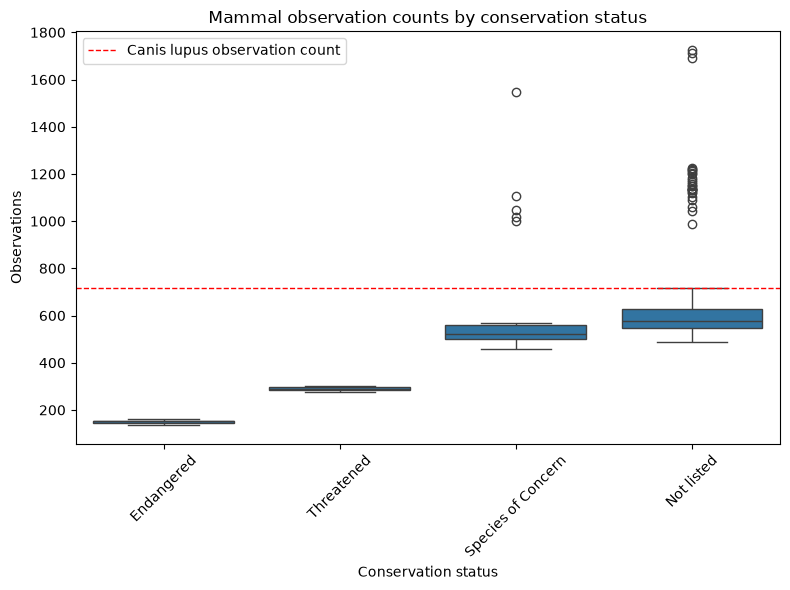

In [5]:
# Keep conservation statuses in a consistent risk order on the x-axis.
risk_order = ["Endangered", "Threatened", "Species of Concern", "Not listed"]

# Restrict the data to mammals.
mammals = df.loc[df["category"] == "Mammal"]

# Create a figure and axes for the boxplot.
fig, ax = plt.subplots(figsize=(8, 6))

# Compare observation counts across conservation statuses.
sns.boxplot(
    data=mammals,
    x="conservation_status",
    y="observations",
    order=risk_order,
    ax=ax
)

# Calculate the observation count for gray wolves.
wolf_count = mammals.loc[
    mammals["scientific_name"] == "Canis lupus",
    "observations"
].mean()

# Add the wolf observation count as a reference line when data is available.
if not pd.isna(wolf_count):
    ax.axhline(
        y=wolf_count,
        color="red",
        linestyle="--",
        linewidth=1,
        label="Canis lupus observation count"
    )
    ax.legend()

# Add the chart title and axis labels.
ax.set(
    title="Mammal observation counts by conservation status",
    xlabel="Conservation status",
    ylabel="Observations"
)

# Rotate category labels to make them easier to read.
ax.tick_params(axis="x", rotation=45)

# Adjust spacing, then display the chart.
fig.tight_layout()
plt.show()

In [6]:
df.loc[df["scientific_name"] == "Canis lupus"]

,scientific_name,observations,category,conservation_status
804,Canis lupus,715,Mammal,Not listed


In [7]:
df.loc[df["category"] == "Mammal"].groupby("conservation_status")["observations"].describe()

,count,mean,std,min,25%,50%,75%,max
conservation_status,,,,,,,,
Endangered,5.0,149.600000,8.820431,137.0,145.0,153.0,153.0,160.0
Not listed,147.0,686.816327,263.201939,487.0,547.5,577.0,629.5,1725.0
Species of Concern,22.0,654.909091,290.308032,458.0,499.5,522.0,560.5,1547.0
Threatened,2.0,289.000000,18.384776,276.0,282.5,289.0,295.5,302.0


**Group sizes (mammals):** Endangered = 5, Threatened = 2, Species of Concern = 22, Not listed = 147. The Endangered and Threatened groups are very small, so their boxes and whiskers should be read cautiously.

### Interpretation
- **Record:** *Canis lupus* has a single record: **715 observations**, category *Mammal*, conservation status *Not listed*.
- **Distance from at-risk groups:** The wolf's count is far above both *Endangered* (mean ≈ 150, max 160) and *Threatened* (mean ≈ 289, max 302) mammals. On observation counts alone, it does not resemble either group.
- **Fit with the labelled group:** At 715, the wolf is above the *Not listed* mean (≈ 687), median (577) and 75th percentile (629.5), but it is not an outlier, since several *Not listed* mammals exceed 1,000 observations. It is also above the 75th percentile of *Species of Concern* (560.5), so counts alone cannot clearly separate these two groups.
- **Red dashed line:** Marks the *Canis lupus* observation count (715). Because there is only one record, this value is simply that single observation, not an average.

**Conclusion:** The wolf's observation count is **consistent with** mammals labelled *Not listed* and inconsistent with *Endangered* or *Threatened* mammals. This is a plausibility check, not a validation. Counts do not determine conservation status, and a blank status in this dataset may simply mean none was recorded. The label is worth checking against an external conservation source.

### **5.2 Review records for *Oncorhynchus mykiss***
**Goal:** Check whether the *Oncorhynchus mykiss* (rainbow trout) observation count is similar to fish labelled *Not listed*, by comparing it with fish in each conservation status.

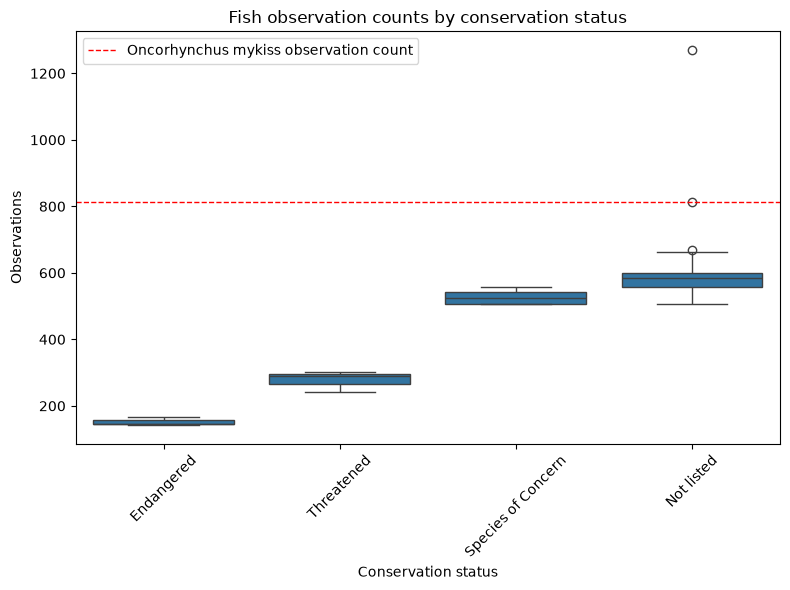

In [8]:
# Keep conservation statuses in a consistent risk order on the x-axis.
risk_order = ["Endangered", "Threatened", "Species of Concern", "Not listed"]

# Restrict the data to fish.
fish = df.loc[df["category"] == "Fish"]

# Create a figure and axes for the boxplot.
fig, ax = plt.subplots(figsize=(8, 6))

# Compare fish observation counts across conservation statuses.
sns.boxplot(
    data=fish,
    x="conservation_status",
    y="observations",
    order=risk_order,
    ax=ax
)

# Calculate the observation count for rainbow trout.
fish_count = fish.loc[
    fish["scientific_name"] == "Oncorhynchus mykiss",
    "observations"
].mean()

# Add the species observation count as a reference line when data is available.
if not pd.isna(fish_count):
    ax.axhline(
        y=fish_count,
        color="red",
        linestyle="--",
        linewidth=1,
        label="Oncorhynchus mykiss observation count"
    )
    ax.legend()

# Add the chart title and axis labels.
ax.set(
    title="Fish observation counts by conservation status",
    xlabel="Conservation status",
    ylabel="Observations"
)

# Rotate category labels to make them easier to read.
ax.tick_params(axis="x", rotation=45)

# Adjust spacing, then display the chart.
fig.tight_layout()
plt.show()

In [9]:
df.loc[df["scientific_name"] == "Oncorhynchus mykiss"]

,scientific_name,observations,category,conservation_status
3430,Oncorhynchus mykiss,813,Fish,Not listed


In [10]:
df.loc[df["category"] == "Fish"].groupby("conservation_status")["observations"].describe()

,count,mean,std,min,25%,50%,75%,max
conservation_status,,,,,,,,
Endangered,3.0,151.666667,12.503333,143.0,144.50,146.0,156.0,166.0
Not listed,115.0,586.278261,76.822368,506.0,556.50,584.0,599.5,1270.0
Species of Concern,4.0,527.250000,25.091499,505.0,507.25,523.5,543.5,557.0
Threatened,3.0,277.333333,31.182260,242.0,265.50,289.0,295.0,301.0


**Group sizes (fish):** Endangered = 3, Threatened = 3, Species of Concern = 4, Not listed = 115. The three at-risk groups are very small, so comparisons with them are indicative only.

#### Interpretation:
- **Record:** *Oncorhynchus mykiss* has a single record: **813 observations**, category *Fish*, conservation status *Not listed*.
- **Distance from at-risk groups:** The count is far above *Endangered* (mean ≈ 152, max 166), *Threatened* (mean ≈ 277, max 301) and *Species of Concern* (mean ≈ 527, max 557) fish. On observation counts alone, it does not resemble any of these groups.
- **Fit with the labelled group:** At 813, the trout is well above the *Not listed* mean (≈ 586), median (584) and 75th percentile (599.5). It is also above the upper whisker (≈ 665), so it appears as an **outlier** on the box plot. It is not the most extreme value in its group, though: the *Not listed* maximum is 1,270.
- **Red dashed line:** Marks the *Oncorhynchus mykiss* observation count (813). Because there is only one record, this value is simply that single observation, not an average.

**Conclusion:** The trout's observation count is **consistent with** fish labelled *Not listed* and inconsistent with *Endangered*, *Threatened* or *Species of Concern* fish. Its count is unusually high even among *Not listed* fish, which may reflect a commonly recorded species or heavier survey effort. This is a plausibility check, not a validation, and the label is worth checking against an external conservation source.

## **6. Summary of findings**
- Average observation counts are lowest for Endangered species in every category and generally rise as risk falls, with Not listed species highest.
- This pattern is consistent across the categories where multiple statuses are present, though not every category has every status.
- *Canis lupus* (715) and *Oncorhynchus mykiss* (813) both have counts far above the Endangered and Threatened groups and in line with, or above, the Not listed groups. The trout is a mild outlier within Not listed fish.
- These results describe the records in this dataset only. They do not show population size or explain why a species has a given status.

## **7. Limitations and next steps**

**Limitations**

- Observation counts reflect survey effort, detectability, and park coverage, not just how common a species is.
- Several at-risk groups are very small (as few as 2 to 5 species), so their averages and box plots are unstable.
- "Not listed" combines species with no recorded status. The dataset does not define it, so it may not mean "not at risk".
- Each species has one count, so the data has no time or per-park dimension.

**Possible next steps**

- Check the wolf and trout labels, and the Not listed group more broadly, against an external conservation source.
- Add group counts (`n`) to the chart or a summary table.
- Normalize counts by park or survey effort, if that data becomes available.
- Test whether the differences between status groups are statistically meaningful, for example with a non-parametric test such as Kruskal-Wallis.